In [127]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os, json

SEED = 42
TARGET = 'stroke'
pd.set_option('display.max_columns', None)

# Modul A - Data understanding & EDA
## A.1 Memuat data

In [128]:
df_raw = pd.read_csv('healthcare-dataset-stroke-data.csv')
df = df_raw.copy()
print('ukuran dataset:', df.shape)
df.sample(5)

ukuran dataset: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2439,49574,Female,56.0,0,0,Yes,Private,Rural,227.04,23.0,smokes,0
3385,6973,Male,11.0,0,0,No,children,Rural,87.54,24.4,Unknown,0
1055,58138,Male,57.0,0,0,Yes,Private,Rural,111.64,31.5,never smoked,0
4975,42297,Female,36.0,0,0,Yes,Private,Urban,124.31,26.4,Unknown,0
4682,3609,Male,78.0,0,0,Yes,Private,Urban,80.44,29.0,never smoked,0


In [129]:
df.info()

df['hypertension'].value_counts()
df['heart_disease'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


heart_disease
0    4834
1     276
Name: count, dtype: int64

**Informasi mengenai datset:**
- **Label** = stroke (0 = tidak, 1 = iya)
- **Numerik** = age, avg_glucose_level, bmi
- **Katagorikal** = ever_married, work_type, Residence_type, smoking_status
- **Biner(0/1)** = hypertension, heart_disease
- **Bukan fitur(yang akan dihapus)** = id, tidak ada kaitannya dengan stroke

## A.2 Cek label pertama kali

stroke
0    4861
1     249
Name: count, dtype: int64

Persentase stroke: 4.87%


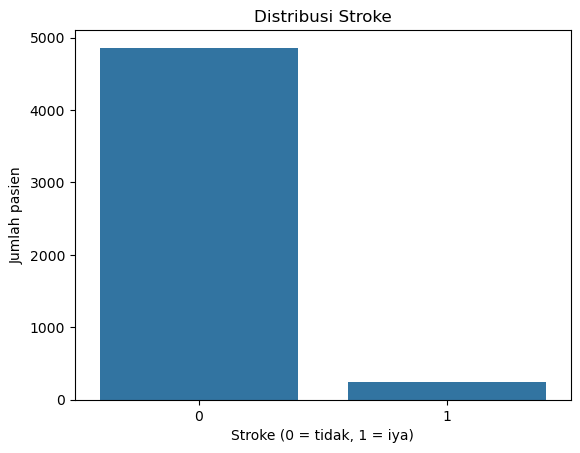

In [130]:
print(df[TARGET].value_counts())
print(f'\nPersentase stroke: {df[TARGET].mean() * 100:.2f}%')

sns.countplot(x=TARGET, data=df)
plt.title('Distribusi Stroke')
plt.xlabel('Stroke (0 = tidak, 1 = iya)')
plt.ylabel('Jumlah pasien')
plt.show()

**Insight - Data tidak seimbang (95:5).** Hanya 249 dari 5.100 pasien (4.87%) yang stroke

## A.3 Audit kualitas data

In [131]:
print('Missing values per kolom:')
print(df.isna().sum()[df.isna().sum() > 0])

print('\nDuplikat baris:', df.duplicated().sum())
print('Duplikat id pasien:', df['id'].duplicated().sum())

for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(f'\n{col}:', df[col].value_counts().to_dict())

Missing values per kolom:
bmi    201
dtype: int64

Duplikat baris: 0
Duplikat id pasien: 0

gender: {'Female': 2994, 'Male': 2115, 'Other': 1}

ever_married: {'Yes': 3353, 'No': 1757}

work_type: {'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}

Residence_type: {'Urban': 2596, 'Rural': 2514}

smoking_status: {'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}


In [132]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [133]:
print('BMI > 60:', (df['bmi'] > 60).sum(), 'baris (maks:', df['bmi'].max(), ')')
print('usia < 1 tahun:', (df['age'] < 1).sum(), 'baris (min:', df['age'].min(), ')')

kosong = df['bmi'].isnull()
print(f'\nStroke jika bmi kosong: {df.loc[kosong, TARGET].mean() * 100:.1f}%')
print(f'Stroke jika bmi tidak kosong: {df.loc[~kosong, TARGET].mean() * 100:.1f}%')

hilang = df.loc[kosong, TARGET].sum() / df[TARGET].sum()
print(f'Jika melakukan dropna: {kosong.mean() * 100:.1f}% baris hilang, tapi {hilang * 100:.1f}% kasus stroke ikut hilang')

BMI > 60: 13 baris (maks: 97.6 )
usia < 1 tahun: 43 baris (min: 0.08 )

Stroke jika bmi kosong: 19.9%
Stroke jika bmi tidak kosong: 4.3%
Jika melakukan dropna: 3.9% baris hilang, tapi 16.1% kasus stroke ikut hilang


**Keputusan Cleaning data**
- **id** = drop kolom, karena tidak ada hubungannya dengan stroke
- **gender - other** = drop baris, 1 data dari other tidak bisa untuk dipelajari
- **bmi kosong** = jangan di drop tapi di isi dengan median dari data latih, karena kalau di drop akan menghilangkan 16% kasus stroke
- **bmi > 60** = dibiarkan, karena kemungkin pasien terjadi penyakit obesitas yang esktrem
- **smoking_status - unkown** = dibuat menjadi kategori tersendiri, karena jika di drop akan membuang data yang banyak
- **usia < 1** = dibuat kategori sendiri, karena kemungkinan itu adalah bayi
- **Duplikat** = tidak ada duplikat data

In [134]:
df = df_raw.drop(columns=['id'])
df = df[df['gender'] != 'Other'].reset_index(drop=True)
print('ukuran dataset setelah drop kolom id dan baris gender Other:', df.shape)
print('kolom:', df.columns.tolist())

ukuran dataset setelah drop kolom id dan baris gender Other: (5109, 11)
kolom: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


## A.4 EDA

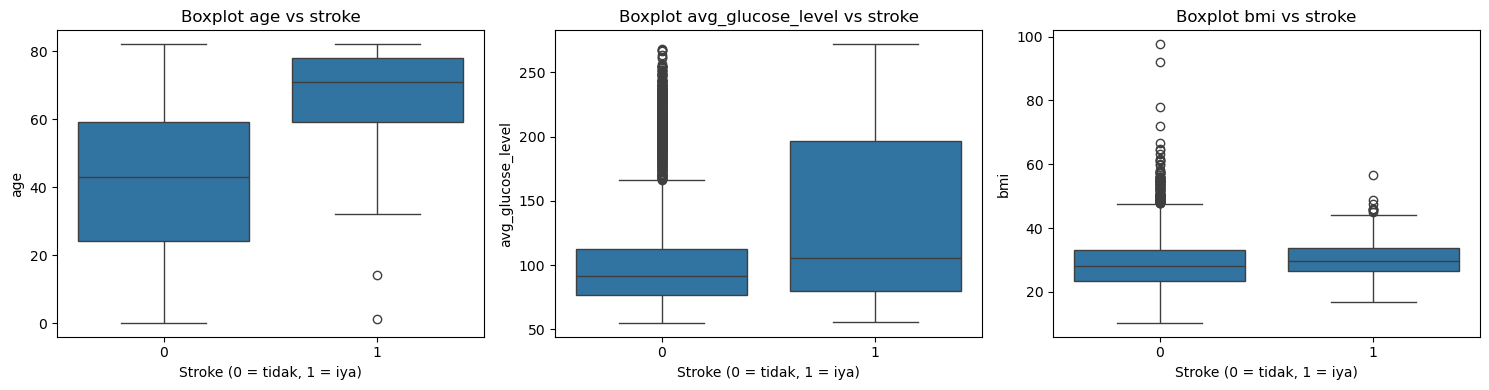

         age  avg_glucose_level   bmi
stroke                               
0       43.0             91.465  28.0
1       71.0            105.220  29.7


In [135]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax)
    ax.set_title(f'Boxplot {col} vs {TARGET}')
    ax.set_xlabel('Stroke (0 = tidak, 1 = iya)')
plt.tight_layout()
plt.show()
print(df.groupby(TARGET)[num_cols].median())

**Insight - Usia adalah pembeda yang terkuat.** Median usia 71 tahun(stroke) vs 43 tahun(tidak). Gula darah lebih tinggi (105 vs 91). BMI hampir sama (29,7 vs 28), jadi diduga fiturnya lemah.Titik yang diatas dari gula darang adalah outlier statistik, bukan data yang salah. Itu adalah kelompok gula darah tinggi(kemungkinan adalah pengidap diabetes), jadi dipertahankan saja.

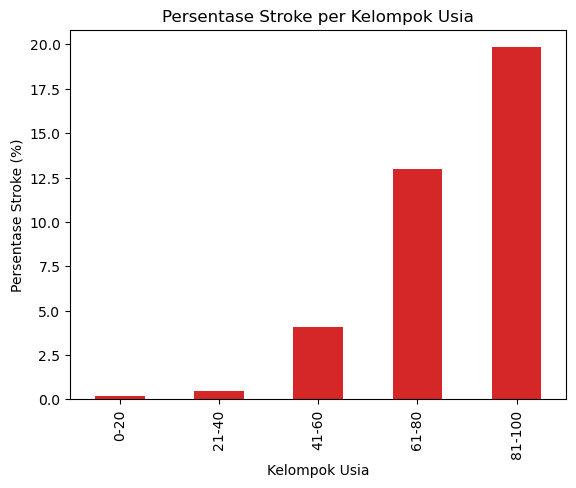

age
0-20       0.20
21-40      0.49
41-60      4.10
61-80     12.96
81-100    19.83
Name: stroke, dtype: float64


In [136]:
kelompok_usia = pd.cut(df['age'], bins=[0, 20, 40, 60, 80, 100], labels=['0-20', '21-40', '41-60', '61-80', '81-100'])
tingkat = df.groupby(kelompok_usia, observed=True)[TARGET].mean() * 100
tingkat.plot(kind='bar', color='tab:red')
plt.title('Persentase Stroke per Kelompok Usia')
plt.xlabel('Kelompok Usia')
plt.ylabel('Persentase Stroke (%)')
plt.show()
print(tingkat.round(2))

**Insight - Semakin usia bertambah, semakin tinggi risiko stroke.** Di bawah 40 tahun, kurang dari 1% pasien stroke. Di usia 60–80 naik ke 13%, dan di atas 80 tahun sekitar 20%, yaitu 1 dari 5 orang. Risikonya selalu naik dan tidak pernah turun, jadi usia akan menjadi fitur paling penting untuk model.

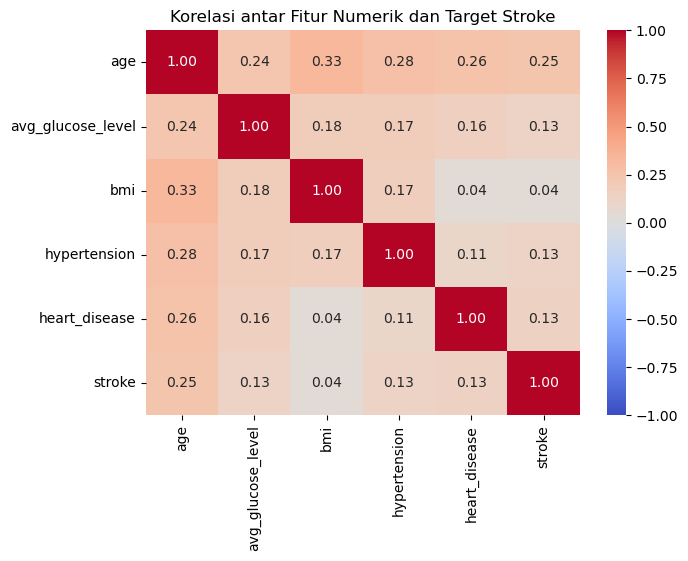

In [137]:
corr = df[num_cols + ['hypertension', 'heart_disease', TARGET]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar Fitur Numerik dan Target Stroke')
plt.show()


**Insight - kolerasi dengan label lemah** (tertinggi usia 0,25). Ini wajar untuk label yang jarang. Antar-fitur juga tidak ada korelasi yang tinggi (maks 0,33), jadi tidak ada masalah multikolinearitas untuk regresi logistik.

In [138]:
df.to_csv('df_cleaned.csv', index=False)
print('tersimpan: df_cleaned.csv', df.shape, '| BMI kosong', df['bmi'].isna().sum(), '- akan diisi di Modul B')

tersimpan: df_cleaned.csv (5109, 11) | BMI kosong 201 - akan diisi di Modul B


# Modul B - Klasifikasi
## B.1 Split data strastified 70 / 15 / 15

**Strastified** dikarenakan data target memiliki perbedaan nilai yang besar diantara kategori 4861 sehat vs 249 stroke jadi perlu di strastified agar pengacakan adil

**70 / 15 / 15** agar ia tetap dapat data training yang memiliki kuantitas yang mumpuni baik bagi Training, Validate, dan Testing

In [139]:
df['stroke'].value_counts()

stroke
0    4860
1     249
Name: count, dtype: int64

In [140]:
def strastified_split(y, fracs=(0.70, 0.15, 0.15), seed=SEED):
    rng = np.random.default_rng(seed)
    parts = [[], [], []]
    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])
        n_tr = int(round(fracs[0] * len(idx)))
        n_va = int(round(fracs[1] * len(idx)))
        parts[0].append(idx[:n_tr])
        parts[1].append(idx[n_tr:n_tr + n_va])
        parts[2].append(idx[n_tr + n_va:])
    return  [rng.permutation(np.concatenate(p)) for p in parts]

idx_tr, idx_va, idx_te = strastified_split(df['stroke'].values)
train_df, val_df, test_df = df.iloc[idx_tr].copy(), df.iloc[idx_va].copy(), df.iloc[idx_te].copy()

bagian = {'semua': df, 'latih (70%)': train_df, 'validasi (15%)': val_df, 'uji (15%)': test_df}
print(pd.DataFrame({'jumlah': [len(d) for d in bagian.values()],
                    'stroke': [d['stroke'].sum() for d in bagian.values()],
                    '% stroke': [round(d['stroke'].mean() * 100, 2) for d in bagian.values()]}, index=bagian.keys()))

                jumlah  stroke  % stroke
semua             5109     249      4.87
latih (70%)       3576     174      4.87
validasi (15%)     766      37      4.83
uji (15%)          767      38      4.95


## B.2 Model

**writefile** dipakai agar kode model tersimpan ke file `model_lr.py`, jadi GUI bisa memakai kode yang sama persis dengan notebook

**Preprocessor** mempelajari parameter dari data latih saja agar tidak terjadi data leakage.

**LogisticRegression** adalah model logistic regression yang ditulis dari nol. Model menghitung skor dari fitur, mengubahnya jadi peluang dengan sigmoid, mengukur kesalahan dengan binary cross entropy, lalu memperbaiki bobot dengan gradient descent

**StrokeModel** menggabungkan preprocessor, model, dan threshold jadi satu paket yang bisa disimpan ke JSON dan dimuat kembali oleh GUI

### Langkah yang akan kita lakukan:
1. **Imputasi BMI**, diinput dengan median BMI **PER** kelompok usia
2. **Encoding biner** `gender` -> `is_male`, `ever_married` -> 1/0, `Residence_type` -> `is_urban`
3. **One-Hot encoding** untuk `work_type` dan `smoking_status` dengan **MEMBUANG** kategori pertama/dijadikan baseline untuk mencegah yang namanya dummy variable trap. Selain itu penggunaan one-hot encoding dan bukannnya label encoding dikarenakan label encoding memakasa ururtan dan jarak yang sama (Misal di column `smoking_status` Unkown < never < formely < smokes) dan juga datanya tidak akurat/kasar (1544 orang status smokingnya unknown, dan juga w2925 orang tidak memberitahu work_type mereka (private))
4. **Normalisasi dengan z-score**, dikarenakan gradient descent memakai **satu learning rate untuk semua bobot**. Jika usia (0-82) dan glukosa (55-272) tidak disakalakan, gradiennya timpang dan training lambat atau zig-zag. Setelah z-score, besar koefisien juga bisa dibandingkan antar fitur. Z-score dipilih daripada min-max karena glukosa punya outlier yang dipertahankan; min-max akan "menekan" mayoritas data ke rentang sempit.

In [141]:
%%writefile model_lr.py
import json
import numpy as np
import pandas as pd

AGE_BINS = [0, 13, 18, 30, 45, 60, 200]
AGE_LABELS = ['0-12', '13-17','18-29', '30-44', '45-59', '60+']

class Preprocessor:
    """Semua parameter dipelajari dari data training jadi tidak ada data leakage"""
    NUM = ['age', 'avg_glucose_level', 'bmi']
    ONESHOT = {'work_type': 'Private', 'smoking_status': 'never smoked'}  # Nilai diambil dari data yang jumlahnya paling banyak

    def fit(self, d):
        grp = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS, right=False)
        self.bmi_median = d.groupby(grp, observed=False)['bmi'].median().to_dict()
        d = self._impute(d)
        self.mean = d[self.NUM].mean().to_dict()
        self.std = d[self.NUM].std().to_dict()
        self.categories = {c: sorted(v for v in d[c].unique() if v != base)
                            for c, base in self.ONESHOT.items()}
        return self

    def _impute(self, d):
        d = d.copy()
        grp = pd.cut(d['age'], bins=AGE_BINS, labels=AGE_LABELS, right=False).astype(str)
        d['bmi'] = d['bmi'].fillna(grp.map(self.bmi_median))
        return d

    def transform(self, d):
        d = self._impute(d)
        X = pd.DataFrame(index=d.index)
        for c in self.NUM:
            X[c] = (d[c] - self.mean[c]) / self.std[c]
        X['hypertension'] = d['hypertension']
        X['heart_disease'] = d['heart_disease']
        X['is_male'] = (d['gender'] == 'Male').astype(int)
        X['ever_married'] = (d['ever_married'] == 'Yes').astype(int)
        X['is_urban'] = (d['Residence_type'] == 'Urban').astype(int)
        for c, cats in self.categories.items():
            for v in cats:
                X[f'{c}={v}'] = (d[c] == v).astype(int)
        return X.astype(float)

class LogisticRegression:
    def __init__(self, lr=0.1, epochs=2000, class_weight=None):
        self.lr, self.epochs, self.class_weight = lr, epochs, class_weight

    @staticmethod
    def sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def _sample_weight(self, y):
        if self.class_weight is None:
            return np.ones_like(y)
        return np.where(y == 1, self.class_weight[1], self.class_weight[0])

    def loss(self, X, y, w=None, b=None):
        w = self.w if w is None else w
        b = self.b if b is None else b
        p = np.clip(self.sigmoid(X @ w + b), 1e-12, 1 - 1e-12)
        s = self._sample_weight(y)
        return -np.sum(s * (y * np.log(p) + (1 - y) * np.log(1 - p))) / s.sum()

    def gradient(self, X, y, w, b):
        s = self._sample_weight(y)
        err = s * (self.sigmoid(X @ w + b) - y)
        return X.T @ err / s.sum(), err.sum() / s.sum()

    def fit(self, X, y, X_val=None, y_val=None):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.history = {'train': [], 'val': []}
        for _ in range(self.epochs):
            self.history['train'].append(self.loss(X, y))
            if X_val is not None:
                self.history['val'].append(self.loss(X_val, y_val))
            dw, db = self.gradient(X, y, self.w, self.b)
            self.w -= self.lr * dw
            self.b -= self.lr * db
        return self

    def predict_proba(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

class StrokeModel:
    """Paket siap pakai: preprocessing + model + threshold. Dipakai notebook DAN GUI."""

    def __init__(self, prep, model, threshold, fitur=None):
        self.prep, self.model, self.threshold, self.fitur = prep, model, threshold, fitur

    def skor(self, data):
        """data mentah (DataFrame, atau dict untuk 1 pasien) -> skor risiko 0..1"""
        if isinstance(data, dict):
            data = pd.DataFrame([data])
        X = self.prep.transform(data)
        if self.fitur is not None:          # pakai fitur terpilih saja (hasil seleksi fitur di Modul C)
            X = X[self.fitur]
        return self.model.predict_proba(X.values)

    def prediksi(self, data):
        return (self.skor(data) >= self.threshold).astype(int)

    def save(self, path, **info):
        isi = {'preprocessing': vars(self.prep), 'weights': self.model.w.tolist(),
               'bias': float(self.model.b), 'threshold': self.threshold, 'fitur': self.fitur, **info}
        with open(path, 'w') as f:
            json.dump(isi, f, indent=2)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            isi = json.load(f)
        prep = Preprocessor()
        prep.__dict__.update(isi['preprocessing'])
        model = LogisticRegression()
        model.w, model.b = np.array(isi['weights']), isi['bias']
        return cls(prep, model, isi['threshold'], isi.get('fitur'))

Overwriting model_lr.py


In [142]:
%run model_lr.py
prep = Preprocessor().fit(train_df)
X_train_df, X_val_df, X_test_df = prep.transform(train_df), prep.transform(val_df), prep.transform(test_df)
y_train, y_val, y_test = (d['stroke'].values.astype(float) for d in (train_df, val_df, test_df))
FEATURES_ALL = list(X_train_df.columns)

print('Median BMI per kelompok usia (dari train):', {k: round(v, 1) for k, v in prep.bmi_median.items()})
print('Sisa NaN setelah transform:', int(X_train_df.isna().sum().sum() + X_val_df.isna().sum().sum() + X_test_df.isna().sum().sum()))
print('Jumlah fitur:', len(FEATURES_ALL))
X_train_df.head()

Median BMI per kelompok usia (dari train): {'0-12': 18.6, '13-17': 23.9, '18-29': 26.6, '30-44': 29.8, '45-59': 30.3, '60+': 29.4}
Sisa NaN setelah transform: 0
Jumlah fitur: 15


,age,avg_glucose_level,bmi,hypertension,heart_disease,is_male,ever_married,is_urban,work_type=Govt_job,work_type=Never_worked,work_type=Self-employed,work_type=children,smoking_status=Unknown,smoking_status=formerly smoked,smoking_status=smokes
774,-0.535635,-1.117478,0.468199,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3280,-1.683740,-0.709851,-1.526767,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1574,1.363154,-0.875962,0.715940,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2306,-0.403161,-0.419376,1.237499,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2691,0.082575,-0.053714,0.468199,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [143]:
print('Cek normalisasi di train (harus mean ~0, std ~1):')
print(X_train_df[Preprocessor.NUM].agg(['mean', 'std']).round(3))

Cek normalisasi di train (harus mean ~0, std ~1):
      age  avg_glucose_level  bmi
mean -0.0                0.0  0.0
std   1.0                1.0  1.0


## B.3 Membuktikan training berjalan dengan benar

**Loss awal = ln 2 (0,693)**

**Gradient check** membuktikan gradien analitik (dari rumus) sama dengan gradien numerik

**Kurva loss** latih dan validasi harus turun lalu stabil

In [144]:
Xtr, Xva, Xte = X_train_df.values, X_val_df.values, X_test_df.values

# Bukti 1: dengan w=0 dan b=0, semua prediksi 0.5 -> loss harus ln(2)
m = LogisticRegression()
print(f'Loss awal = {m.loss(Xtr, y_train, np.zeros(Xtr.shape[1]), 0.0):.4f} | ln 2 = {np.log(2):.4f}')

# Bukti 2: gradoemt check dengan beda yang sangat kecil
rng = np.random.default_rng(SEED)
w0, b0, eps = rng.normal(0, 0.1, Xtr.shape[1]), 0.1, 1e-5
dw, _ = m.gradient(Xtr, y_train, w0, b0)
num = np.array([(m.loss(Xtr, y_train, w0 + eps * e, b0) - m.loss(Xtr, y_train, w0 - eps * e, b0)) / (2 * eps)
                for e in np.eye(len(w0))])
print(f'Selisih maksimum gradien analitik vs numerik {np.max(np.abs(dw - num)):.2e} (Harus sangat kecil)')

Loss awal = 0.6931 | ln 2 = 0.6931
Selisih maksimum gradien analitik vs numerik 1.17e-11 (Harus sangat kecil)


Loss train: 0.6931 -> 0.1585
Loss val  : 0.6931 -> 0.1565


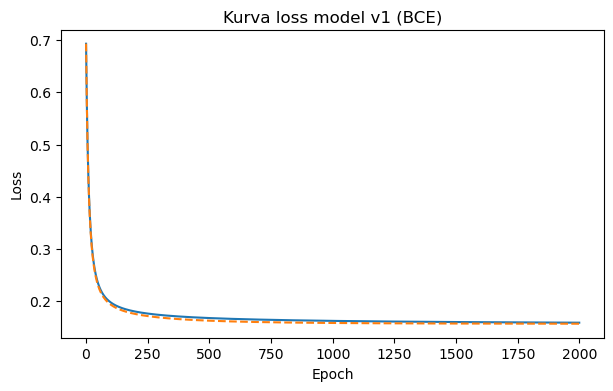

In [145]:
# Bukti 3 loss turun dan stabil

model_v1 = LogisticRegression(lr=0.1, epochs=2000).fit(Xtr, y_train, Xva, y_val)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(model_v1.history['train'], label='train')
ax.plot(model_v1.history['val'], label='validasi', ls='--')
ax.set_title('Kurva loss model v1 (BCE)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
print(f"Loss train: {model_v1.history['train'][0]:.4f} -> {model_v1.history['train'][-1]:.4f}")
print(f"Loss val  : {model_v1.history['val'][0]:.4f} -> {model_v1.history['val'][-1]:.4f}")

# Modul C - Evaluasi Model
## C.1 Confusion matrix dan metrik tanpa library

**True Positive (TP)** = pasien stroke yang tertangkap

**False Negative (FN)** = pasien stroke yang terlewat, ini kesalahan **paling berbahaya**

**False Positive (FP)** = pasien sehat yang diberi alarm palsu

**True Negative (TN)** = pasien sehat yang benar dinyatakan sehat

1. **Recall** = TP / (TP + FN): Dari semua pasien stroke berapa yang tertangkap
2. **Precision** = TP / (TP + FP): dari yang diberi alarm berapa yang benar benar stroke
3. **F1** = rata-rata harmonik precision dan recall safe_div(2 * prec * rec, prec + rec)
4. **F2** = F1 yang lebih membobotkan pada recall daripada precision safe_div(5 * prec * rec, (4 * prec) + rec)
4. **AUC (ROC)**: Peluang model memberi skor lebih tinggi ke pasien stroke daripada pasien sehat

**Pilihan metrik** = ini alat skrining, jadi pasien stroke yang terlewat jauh lebih berbahaya daripada alarm palsu. Karena itu **recall menjadi metrik utama**, dengan precision dan F1 sebagai penyeimbang

In [146]:
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

def safe_div(a, b):
    return a / b if b else 0.0

def roc_auc(y_true, score):
    ranks = pd.Series(score).rank().values          # rank rata-rata untuk nilai yang sama
    pos = np.asarray(y_true) == 1
    n_pos, n_neg = pos.sum(), (~pos).sum()
    return (ranks[pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def evaluate(y_true, proba, threshold=0.5):
    tp, fn, fp, tn = confusion_matrix(y_true, proba >= threshold)
    prec, rec = safe_div(tp, tp + fp), safe_div(tp, tp + fn)
    return {'threshold': threshold, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
            'accuracy': (tp + tn) / (tp + fn + fp + tn), 'precision': prec, 'recall': rec,
            'specificity': safe_div(tn, tn + fp), 'f1': safe_div(2 * prec * rec, prec + rec), 'f2': safe_div(5 * prec * rec, (4 * prec) + rec),
            'auc': float(roc_auc(y_true, proba))}

def plot_cm(ax, y_true, proba, threshold, title):
    tp, fn, fp, tn = confusion_matrix(y_true, proba >= threshold)
    cm = np.array([[tp, fn], [fp, tn]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Prediksi stroke', 'Prediksi tidak'],
                yticklabels=['Aktual stroke', 'Aktual tidak'], annot_kws={'size': 13})
    ax.set_title(title)

## C.2 Evaluasi model v1 (baseline) di data validasi


In [147]:
p_val_v1 = model_v1.predict_proba(Xva)
res_v1 = evaluate(y_val, p_val_v1, 0.5)
baseline_acc = 1 - y_val.mean()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_v1.items()})

print(f'Hasil evaluasi model -> akurasi {baseline_acc:.3f}, recall 0')

{'threshold': 0.5, 'TP': 0, 'FN': 37, 'FP': 0, 'TN': 729, 'accuracy': 0.952, 'precision': 0.0, 'recall': 0.0, 'specificity': 1.0, 'f1': 0.0, 'f2': 0.0, 'auc': 0.842}
Hasil evaluasi model -> akurasi 0.952, recall 0


**Diagnosis:** akurasi v1 terlihat bagus (~95%), tetapi **recall 0** yang berarti tidak ada satu pun pasien stroke yang terdeteksi. Model v1 sama saja dengan menebak "tidak stroke" untuk semua orang. Sebenarnya AUC-nya cukup baik (~0,8), jadi model sudah bisa **mengurutkan** risiko, hanya saja probabilitasnya tidak pernah melewati 0,5 karena hanya 4,9% data latih yang positif.

Dua penyebab, dua perbaikan:
1. Loss didominasi kelas mayoritas → **class weight**
2. Threshold 0,5 tidak cocok untuk kasus langka → **tuning threshold** di data validasi

## C.3 Perbaikan 1: class weight
Bobot setiap kelas = nTotal / nclass * nJumlahDataKelasItu, nTotal adalah seluruh sampel yang kita miliki sedangkan nclass adalah jumlah jenis kategori dari target kita (ada 2 yaitu stroke dan tidak stroke) Ternyata satu pasien stroke "bernilai" sekitar 10 pasien sehat dalam loss, sehingga kesalahan pada kelas langka tidak bisa diabaikan model.

In [148]:
n, n_pos = len(y_train), y_train.sum()
CLASS_WEIGHT = {0: float(n / (2 * (n - n_pos))), 1: float(n / (2 * n_pos))}
print('Class weight:', {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

model_v2 = LogisticRegression(lr=0.1, epochs=2000, class_weight=CLASS_WEIGHT).fit(Xtr, y_train, Xva, y_val)
res_v2 = evaluate(y_val, model_v2.predict_proba(Xva), 0.5)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res_v2.items()})

Class weight: {0: 0.526, 1: 10.276}
{'threshold': 0.5, 'TP': 29, 'FN': 8, 'FP': 198, 'TN': 531, 'accuracy': 0.731, 'precision': 0.128, 'recall': 0.784, 'specificity': 0.728, 'f1': 0.22, 'f2': 0.387, 'auc': 0.845}


## C.4 Perbaikan 2: pemilihan fitur berbasis bukti
Hipotesis dari Modul-modul sebelumnya bahwa banyak fitur sudah diwakilkan oleh usia. Kita bandingkan fitur dengan AUC (semua memakai class weight): (Berikut fitur yang akan kita pakai usia, glukosa, hipertensi, penyakit jantung )

AUC dipilih karena dia tidak dependent dengan threshold tidak seperti recall atau presicion yang sangat bergantung dengan threshold

In [157]:
FEATURE_SETS = {
    'A (15 kolom)': FEATURES_ALL,
    'B (4 input)': ['age', 'avg_glucose_level', 'hypertension', 'heart_disease'],
}
fs_models, fs_rows = {}, []
for name, feats in FEATURE_SETS.items():
    idx = [FEATURES_ALL.index(f) for f in feats]
    m = LogisticRegression(lr=0.1, epochs=2000, class_weight=CLASS_WEIGHT).fit(Xtr[:, idx], y_train)
    fs_models[name] = (m, idx)
    fs_rows.append({'set': name, 'jumlah_kolom': len(feats), 'auc_val': roc_auc(y_val, m.predict_proba(Xva[:, idx]))})
fs_table = pd.DataFrame(fs_rows).set_index('set')
best_auc = fs_table['auc_val'].max()
eligible = fs_table[fs_table['auc_val'] >= best_auc - 0.01]
CHOSEN = eligible['jumlah_kolom'].idxmin()  
print(fs_table.round(3))
print('\nSet terpilih:', CHOSEN)

m_b, idx_b = fs_models['A (15 kolom)']
print('\nPengaruh fitur pada set A terhadap target:')
print(pd.Series(m_b.w, index=FEATURE_SETS['A (15 kolom)']).round(3).to_string())

              jumlah_kolom  auc_val
set                                
A (15 kolom)            15    0.845
B (4 input)              4    0.859

Set terpilih: B (4 input)

Pengaruh fitur pada set A terhadap target:
age                               1.718
avg_glucose_level                 0.151
bmi                               0.052
hypertension                      0.448
heart_disease                     0.398
is_male                           0.040
ever_married                     -0.180
is_urban                          0.154
work_type=Govt_job               -0.399
work_type=Never_worked           -0.029
work_type=Self-employed          -0.197
work_type=children               -0.003
smoking_status=Unknown            0.244
smoking_status=formerly smoked   -0.136
smoking_status=smokes             0.335


**Hasil:** AUC ketiga set berada dalam rentang 0,01–0,02, dan set paling sederhana (C, 4 input) justru sedikit lebih tinggi. Menambah fitur lemah hanya menambah noise. Set C terpilih.

Koefisien set A juga menunjukkan masalah: `smoking_status=formerly smoked` bernilai **negatif**, seolah pernah merokok menurunkan risiko stroke. Ini konsisten dengan Insight 5: setelah usia masuk ke model, status merokok tidak membawa informasi yang stabil. Jika tetap dipakai, GUI bisa menampilkan penjelasan yang menyesatkan bagi petugas kesehatan ("pernah merokok menurunkan risiko"). Jadi membuang status merokok di sini adalah keputusan **berbasis data dan keamanan pengguna**, bukan klaim medis bahwa merokok tidak berbahaya.

In [150]:
model_final, sel = fs_models[CHOSEN]
FEATURES_FINAL = FEATURE_SETS[CHOSEN]
print('Fitur model final:', FEATURES_FINAL)

Fitur model final: ['age', 'avg_glucose_level', 'hypertension', 'heart_disease']


## C.5 Perbaikan 3: memilih threshold di data validasi
Aturan operasional: **pilih threshold tertinggi yang masih menangkap minimal 80% pasien stroke di data validasi** (recall ≥ 0,80). Threshold lebih tinggi berarti alarm palsu lebih sedikit, jadi di antara threshold yang memenuhi target recall, yang tertinggi adalah yang paling efisien.

Catatan: threshold hasil tuning bisa saja jatuh dekat 0,5. Itu wajar, karena class weight sudah menggeser probabilitas. Yang dinilai bukan angkanya berbeda dari 0,5, melainkan bahwa threshold **dipilih dengan aturan yang jelas di data validasi**, bukan dipakai begitu saja sebagai default.

Threshold terpilih: 0.53
           recall  precision     f1   FP
threshold                               
0.30        0.973      0.103  0.186  315
0.40        0.919      0.119  0.211  252
0.50        0.838      0.133  0.230  202
0.53        0.811      0.138  0.235  188
0.60        0.703      0.159  0.259  138
0.70        0.568      0.172  0.264  101


Text(0, 0.5, 'Skor')

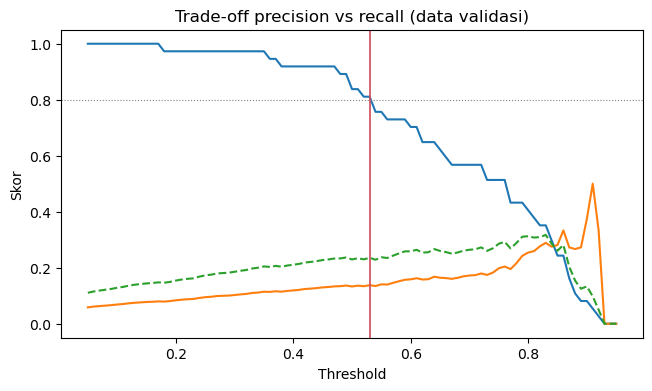

In [151]:
TARGET_RECALL = 0.80
p_val_final = model_final.predict_proba(Xva[:, sel])
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame([evaluate(y_val, p_val_final, t) for t in grid])
ok = curve[curve['recall'] >= TARGET_RECALL]
BEST_T = float(ok['threshold'].max())
print(f'Threshold terpilih: {BEST_T}')
show_t = sorted({0.3, 0.4, 0.5, 0.6, 0.7, BEST_T})
print(curve.set_index('threshold').loc[show_t, ['recall', 'precision', 'f1', 'FP']].round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(curve['threshold'], curve['recall'], label='recall')
ax.plot(curve['threshold'], curve['precision'], label='precision')
ax.plot(curve['threshold'], curve['f1'], label='F1', ls='--')
ax.axhline(TARGET_RECALL, color='grey', lw=0.8, ls=':')
ax.axvline(BEST_T, color='#d1495b', lw=1.2, label=f'threshold terpilih = {BEST_T}')
ax.set_title('Trade-off precision vs recall (data validasi)'); ax.set_xlabel('Threshold'); ax.set_ylabel('Skor')

## C.6 Evaluasi akhir di data uji (sekali saja): sebelum vs sesudah

,TP,FN,FP,TN,accuracy,precision,recall,f1,auc
"v1 baseline (15 kolom, t=0.5)",0.0,38.0,0.0,729.0,0.950,0.000,0.000,0.000,0.838
"v2 + class weight (15 kolom, t=0.5)",33.0,5.0,199.0,530.0,0.734,0.142,0.868,0.244,0.848
FINAL: class weight + 4 input + t=0.53,33.0,5.0,180.0,549.0,0.759,0.155,0.868,0.263,0.850


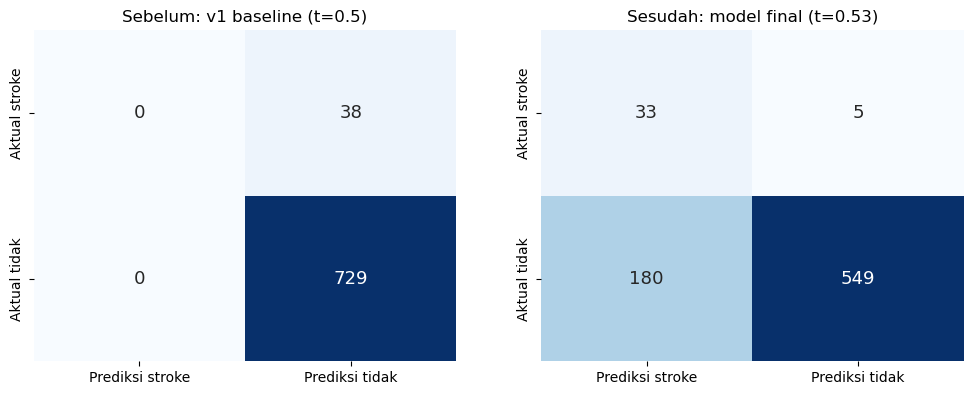

In [152]:
p_test_v1 = model_v1.predict_proba(Xte)
p_test_final = model_final.predict_proba(Xte[:, sel])
FINAL_NAME = f'FINAL: class weight + {len(FEATURES_FINAL)} input + t={BEST_T}'
rows = {
    'v1 baseline (15 kolom, t=0.5)': evaluate(y_test, p_test_v1, 0.5),
    'v2 + class weight (15 kolom, t=0.5)': evaluate(y_test, model_v2.predict_proba(Xte), 0.5),
    FINAL_NAME: evaluate(y_test, p_test_final, BEST_T),
}
comparison = pd.DataFrame(rows).T[['TP', 'FN', 'FP', 'TN', 'accuracy', 'precision', 'recall', 'f1', 'auc']]
display(comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
plot_cm(axes[0], y_test, p_test_v1, 0.5, 'Sebelum: v1 baseline (t=0.5)')
plot_cm(axes[1], y_test, p_test_final, BEST_T, f'Sesudah: model final (t={BEST_T})')

In [153]:
final_res = rows[FINAL_NAME]
base_rate = y_test.mean()
print(f'Pasien stroke tertangkap : {final_res["TP"]} dari {final_res["TP"] + final_res["FN"]} ({final_res["recall"]:.0%})')
print(f'Precision alarm          : {final_res["precision"]:.1%}  vs stroke rate populasi {base_rate:.1%}')
print(f'Lift                     : {final_res["precision"] / base_rate:.1f}x lebih tepat daripada memeriksa pasien secara acak')
print(f'Pasien yang perlu dicek lanjut: {final_res["TP"] + final_res["FP"]} dari {len(y_test)} ({(final_res["TP"] + final_res["FP"]) / len(y_test):.0%})')

Pasien stroke tertangkap : 33 dari 38 (87%)
Precision alarm          : 15.5%  vs stroke rate populasi 5.0%
Lift                     : 3.1x lebih tepat daripada memeriksa pasien secara acak
Pasien yang perlu dicek lanjut: 213 dari 767 (28%)


**Interpretasi:**
- Sebelum perbaikan, model tidak menangkap satu pun pasien stroke. Sesudah perbaikan, model final menangkap sebagian besar pasien stroke di data uji, hanya dengan 4 input.
- Model final menyamai recall v2 (15 kolom) dengan alarm palsu lebih sedikit. Ini konsisten dengan keputusan C.4: 11 kolom tambahan tidak memberi nilai.
- Akurasi **turun**, dan itu disengaja: model sekarang berani memberi alarm. Penurunan akurasi pada kasus tidak seimbang bukan tanda model memburuk.
- Konsekuensinya, sekitar 28% pasien diminta pemeriksaan lanjutan. Precision terlihat rendah, tetapi bandingkan dengan stroke rate populasi: pasien yang diberi alarm oleh model beberapa kali lebih mungkin benar-benar stroke daripada pasien yang dipilih acak. Untuk alat skrining (bukan diagnosis), ini trade-off yang wajar: lebih baik banyak pasien diminta cek lanjutan daripada pasien berisiko terlewat.
- Nilai metrik pada data uji dihitung dari sekitar 38 kasus positif, jadi angka recall bisa bergeser beberapa poin jika data uji diganti. Angkanya perlu dibaca sebagai perkiraan, bukan kepastian.

## C.7 MEnyimpan model (Modul D)

In [154]:
stroke_model = StrokeModel(prep, model_final, BEST_T, fitur=FEATURES_FINAL)
stroke_model.save('model_stroke_lr.json')

# Sanity check: muat ulang dan pastikan prediksi identik
model_load = StrokeModel.load('model_stroke_lr.json')
print('Model tersimpan')

Model tersimpan


## C.8 Konsistensi dengan GUI (Modul D)

**GUI** di `gui_stroke_lr.py` memuat model dengan `StrokeModel.load()` lalu menghitung skor dengan `skor()`, jadi kodenya sama persis dengan notebook. Uji di bawah memastikan skor per pasien (cara GUI) sama dengan skor di notebook untuk seluruh data uji

In [155]:
gui_probs = [float(model_load.skor(r.drop('stroke').to_dict())[0]) for _, r in test_df.iterrows()]
print('Prediksi GUI == prediksi notebook untuk seluruh data uji:', np.allclose(gui_probs, p_test_final))

Prediksi GUI == prediksi notebook untuk seluruh data uji: True
